In [13]:
#import libraries and load data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

daily = pd.read_parquet("../data/clean/returns_daily.parquet")
weekly = pd.read_parquet("../data/clean/returns_weekly.parquet")
assets = pd.read_csv("../data/clean/dim_asset.csv")


print("Asset columns:", assets.columns.tolist())   # must include 'Asset'
print("Daily:", daily.shape, "| Weekly:", weekly.shape)

meta = assets.set_index("Asset")
cat = meta["Category"]


Asset columns: ['Asset', 'Ticker', 'Category', 'Transform']
Daily: (6995, 44) | Weekly: (1399, 44)


In [14]:
#Rolling correlations
def rolling_corr_monthly(returns, window):
    rc = returns.rolling(window, min_periods=int(window * 0.8)).corr()
    month_end = returns.groupby(returns.index.to_period("M")).tail(1).index
    rc = rc[rc.index.get_level_values(0).isin(month_end)]
    long = rc.stack().reset_index()
    long.columns = ["Date", "Asset_A", "Asset_B", "Correlation"]
    long = long[long["Asset_A"] < long["Asset_B"]]
    long["Window"] = window
    return long

rolling = pd.concat([rolling_corr_monthly(daily, w) for w in (60, 120, 250)],
                    ignore_index=True)
rolling["Pair"] = rolling["Asset_A"] + " vs " + rolling["Asset_B"]
rolling = rolling.dropna(subset=["Correlation"])

rolling.to_parquet("../data/clean/rolling_corr_monthly.parquet")
print(rolling.shape)
rolling.head()

(738969, 6)


,Date,Asset_A,Asset_B,Correlation,Window,Pair
1892,2000-03-31,S&P 500,Shanghai,-0.125788,60,S&P 500 vs Shanghai
1896,2000-03-31,S&P 500,USD/JPY,-0.028317,60,S&P 500 vs USD/JPY
1900,2000-03-31,S&P 500,Tech,0.756946,60,S&P 500 vs Tech
1901,2000-03-31,S&P 500,Utilities,0.525785,60,S&P 500 vs Utilities
1902,2000-03-31,S&P 500,Staples,0.570292,60,S&P 500 vs Staples


29 core assets


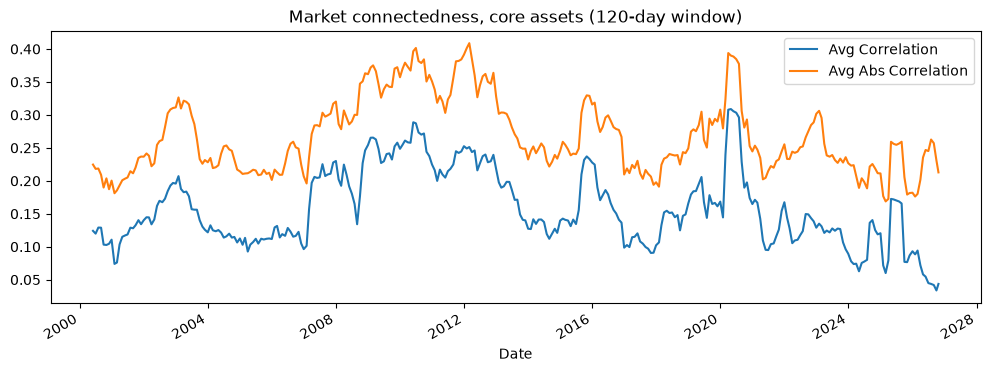

In [ ]:
#Connectedness over time
first = daily.apply(lambda s: s.first_valid_index())
core = first[first <= "2001-01-01"].index.tolist()
print(len(core), "core assets")

w = rolling[(rolling["Window"] == 120)
            & rolling["Asset_A"].isin(core)
            & rolling["Asset_B"].isin(core)].copy()
w["Abs"] = w["Correlation"].abs()

connectedness = w.groupby("Date").agg(
    **{"Avg Correlation": ("Correlation", "mean"),
       "Avg Abs Correlation": ("Abs", "mean"),
       "Pairs Used": ("Correlation", "count")}
).reset_index()

connectedness.plot(x="Date", y=["Avg Correlation", "Avg Abs Correlation"],
                   figsize=(12, 4),
                   title="Market connectedness, core assets (120-day window)")
plt.show()

In [16]:
#Combine the connectedness measures and define regimes
conn = connectedness.copy()
conn["Regime"] = pd.qcut(conn["Avg Correlation"], 3,
                         labels=["Calm", "Elevated", "Stressed"])
conn.to_parquet("../data/clean/connectedness.parquet")
conn.tail()

,Date,Avg Correlation,Avg Abs Correlation,Pairs Used,Regime
313,2026-06-30,0.044795,0.245129,406,Calm
314,2026-07-31,0.043561,0.262633,406,Calm
315,2026-08-31,0.041872,0.257126,406,Calm
316,2026-09-30,0.033662,0.230896,406,Calm
317,2026-10-23,0.043530,0.212785,406,Calm


In [17]:
#Crisis periods
crises = pd.DataFrame([
    ("Calm 2017 (baseline)", "2017-01-03", "2017-12-29"),
    ("Dot-com crash", "2000-03-10", "2002-10-09"),
    ("Global Financial Crisis", "2007-10-09", "2009-03-09"),
    ("Euro debt crisis", "2011-07-01", "2011-10-04"),
    ("China/Oil selloff", "2015-08-10", "2016-02-11"),
    ("COVID crash", "2020-02-19", "2020-03-23"),
    ("Rate-hike bear market", "2022-01-03", "2022-10-12"),
    ("Banking stress", "2023-03-08", "2023-03-31"),
], columns=["Crisis", "Start", "End"])
crises.to_csv("../data/clean/dim_crisis.csv", index=False)

rows = []
for _, c in crises.iterrows():
    sub = daily.loc[c["Start"]:c["End"]].corr(min_periods=15)
    for a in sub.index:
        for b in sub.columns:
            if a < b and pd.notna(sub.loc[a, b]):
                rows.append({"Crisis": c["Crisis"], "Asset_A": a, "Asset_B": b,
                             "Cat_A": cat[a], "Cat_B": cat[b],
                             "Correlation": sub.loc[a, b]})

crisis_corr = pd.DataFrame(rows)
crisis_corr.to_parquet("../data/clean/crisis_corr.parquet")

summary = (crisis_corr.assign(Abs=crisis_corr["Correlation"].abs())
           .groupby("Crisis")
           .agg(Avg_Correlation=("Correlation", "mean"),
                Avg_Abs_Correlation=("Abs", "mean"),
                Pairs=("Correlation", "count"))
           .round(3).sort_values("Avg_Correlation"))
summary

,Avg_Correlation,Avg_Abs_Correlation,Pairs
Crisis,,,
Calm 2017 (baseline),0.064,0.160,903
Dot-com crash,0.076,0.200,496
Banking stress,0.081,0.335,903
Rate-hike bear market,0.108,0.224,903
China/Oil selloff,0.146,0.252,861
Euro debt crisis,0.173,0.352,820
Global Financial Crisis,0.185,0.295,820
COVID crash,0.245,0.384,903


In [18]:
#Safe-haven scorecard
spx = daily["S&P 500"]
bad = daily[spx <= spx.quantile(0.05)].drop(columns="S&P 500")

safe = pd.DataFrame({
    "Avg Return on Bad Days %": bad.mean() * 100,
    "Hit Rate %": (bad > 0).mean() * 100,
    "Observations": bad.count(),
})
safe = safe.rename_axis("Asset").reset_index()

safe["Category"] = safe["Asset"].map(meta["Category"])
safe["Type"] = safe["Asset"].map(meta["Transform"]).map(
    {"log": "Price return", "diff": "Level change"})

# % return is meaningless for VIX and yields; Hit Rate stays valid
safe.loc[safe["Type"] == "Level change", "Avg Return on Bad Days %"] = np.nan
safe["Era"] = "All"

safe.to_parquet("../data/clean/safe_haven.parquet")
safe.sort_values("Hit Rate %", ascending=False).head(12)

,Asset,Avg Return on Bad Days %,Hit Rate %,Observations,Category,Type,Era
42,VIX,NaN,96.857143,350,Volatility,Level change,All
30,Long Treasury ETF,0.840444,66.285714,287,Bonds,Price return,All
17,Dollar Index,0.114588,55.714286,350,Currency,Price return,All
9,Gold,0.069012,50.000000,334,Commodity,Price return,All
6,Shanghai,-0.204413,46.857143,346,Equity Index,Price return,All
32,Corp Bonds,-0.081198,43.428571,287,Bonds,Price return,All
13,Natural Gas,-0.539593,40.000000,334,Commodity,Price return,All
15,Wheat,-0.515669,39.428571,334,Commodity,Price return,All
21,USD/THB,0.064994,38.857143,259,Currency,Price return,All
22,USD/CNY,-0.000574,38.000000,310,Currency,Price return,All


In [19]:
#Fnal Check

import os
needed = ["rolling_corr_monthly.parquet", "connectedness.parquet",
          "crisis_corr.parquet", "safe_haven.parquet", "dim_crisis.csv"]
for f in needed:
    p = "../data/clean/" + f
    print(("OK      " if os.path.exists(p) else "MISSING ") + f)

OK      rolling_corr_monthly.parquet
OK      connectedness.parquet
OK      crisis_corr.parquet
OK      safe_haven.parquet
OK      dim_crisis.csv
